In [2]:
#qt for gui figures, inline for embedded in notebook 
%matplotlib qt
%matplotlib inline 
import hyperspy.api as hs
import exspy
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
s = hs.load("albite_0p078.rpl", stack=True)
s.set_signal_type("EDS_SEM")
s.metadata.General.title = 'Albite Standard for Na'
s


  0%|          | 0/1 [00:00<?, ?it/s]

<EDSSEMSpectrum, title: Albite Standard for Na, dimensions: (1024, 768|2525)>

In [4]:
s.axes_manager.gui()
#enter pixel, and -0.96 offset keV and 0.01 keV, this example scale is 0.078 microns


The inline matplotlib backend is not compatible with the traitsui GUI elements. For more information, read https://hyperspy.readthedocs.io/en/stable/user_guide/basic_usage.html#possible-warnings-when-importing-hyperspy.


/Users/thomaslam/anaconda3/lib/python3.13/site-packages/rsciio/utils/rgb_tools.py:62: VisibleDeprecationWarning: The module `rsciio.utils.rgb_tools` has been renamed to `rsciio.utils.rgb` and it will be removed in version 1.0.
  warnings.warn(


(0.2, 2.5)

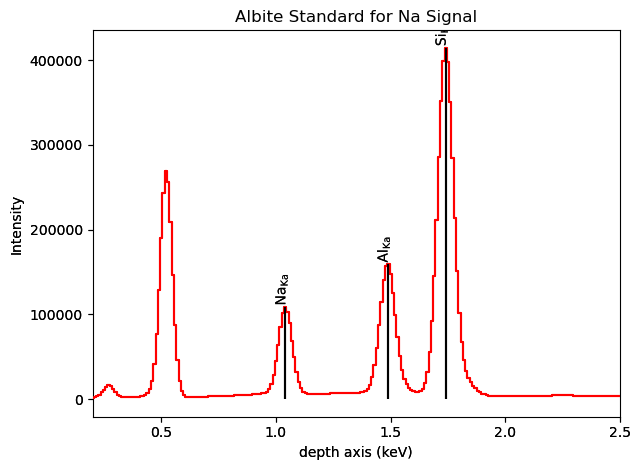

In [5]:
sum_spec = s.sum()
sum_spec.set_elements(["Na", "Al", "Si"])
sum_spec.add_lines(["Na_Ka", "Al_Ka", "Si_Ka"])
sum_spec.plot(True)
sum_spec._plot.signal_plot.ax.set_xlim(0.2, 2.5)


In [6]:
ss = sum_spec
x = ss.axes_manager.signal_axes[0].axis
y = ss.data

left_bg = (x >= 0.7) & (x <= 0.90)
right_bg = (x >= 1.16) & (x <= 1.3)
peak = (x >= 0.96) & (x <= 1.12)

x_bg = np.r_[x[left_bg], x[right_bg]]
y_bg = np.r_[y[left_bg], y[right_bg]]

coef = np.polyfit(x_bg, y_bg, 1)
baseline = np.polyval(coef, x)

y_corr = y - baseline
Na_net = y_corr[peak].sum()

print("Na_net_counts", f"{Na_net:.3f}")

Na_net_counts 760240.984


In [7]:
df = pd.read_csv("15kV_Stds_Lib.csv")
df.iloc[0, 1] = Na_net
df.to_csv("15kV_Stds_Lib.csv", index=False)